# NASA Software Defect Prediction — Chapter 3 Methodology Implementation

Dataset: `bharatkumar0925/nasa-software-defect-prediction` (Kaggle).
Metric-based, no source code available -> **Pipeline A (ML) only**. SVM, Decision Tree, Random Forest.
Pipeline B (CNN/LSTM) needs raw source and does not apply to this dataset.

## 1. Setup

In [1]:
import time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, matthews_corrcoef,
                              confusion_matrix, roc_curve)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## 2. Load data (Section 3.3)

In [2]:
import kagglehub

path = kagglehub.dataset_download("bharatkumar0925/nasa-software-defect-prediction")
print("Path to dataset files:", path)

100%|██████████| 45.6k/45.6k [00:00<00:00, 9.60MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/bharatkumar0925/nasa-software-defect-prediction/versions/1


In [3]:
import os

csv_files = []
for root, _, files in os.walk(path):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, f))
print(csv_files)

train_path = next(f for f in csv_files if "train" in os.path.basename(f).lower())
test_path = next(f for f in csv_files if "test" in os.path.basename(f).lower())

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
print(train.shape, test.shape)
train.head()

['/root/.cache/kagglehub/datasets/bharatkumar0925/nasa-software-defect-prediction/versions/1/nasa-software-defect-prediction-sdp-challenge/Train_data.csv', '/root/.cache/kagglehub/datasets/bharatkumar0925/nasa-software-defect-prediction/versions/1/nasa-software-defect-prediction-sdp-challenge/Test_data.csv']
(1676, 23) (419, 22)


,Index,LOC_BLANK,BRANCH_COUNT,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CYCLOMATIC_COMPLEXITY,DESIGN_COMPLEXITY,ESSENTIAL_COMPLEXITY,LOC_EXECUTABLE,HALSTEAD_CONTENT,...,HALSTEAD_LENGTH,HALSTEAD_LEVEL,HALSTEAD_PROG_TIME,HALSTEAD_VOLUME,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,LOC_TOTAL,Defect
0,0,0,3,0,0,2,2,1,5,17.08,...,18,0.29,11.63,59.79,3,15,3,7,7,1
1,1,1,1,0,0,1,1,1,8,28.00,...,21,0.33,14.00,84.00,10,11,10,6,14,0
2,2,0,1,0,0,1,1,1,0,7.74,...,5,0.67,0.97,11.61,2,3,2,3,2,0
3,3,0,1,0,2,1,1,1,4,6.67,...,10,0.22,7.50,30.00,3,7,2,6,8,0
4,4,2,3,1,3,2,2,1,14,30.86,...,36,0.21,37.33,144.00,12,24,9,7,22,0


## 3. Label detection and distribution analysis (Section 3.3.4)

Column name and positive-class encoding are detected per file rather than assumed, since the two
files are not guaranteed to share identical naming or encoding.

In [4]:
def find_label_col(df):
    candidates = [c for c in df.columns if c.lower() in
                  ("defective", "defect", "defects", "target", "label", "class")]
    return candidates[0] if candidates else df.columns[-1]

def to_binary(series):
    """Maps Y/Yes/True/1/Defective-style positive labels to 1, everything else to 0."""
    if pd.api.types.is_bool_dtype(series) or pd.api.types.is_numeric_dtype(series):
        return series.astype(int)
    pos_vals = {"y", "yes", "true", "1", "defective", "d"}
    return series.astype(str).str.strip().str.lower().isin(pos_vals).astype(int)

train_label_col = find_label_col(train)
test_label_col = find_label_col(test)
print("train label column:", train_label_col, "| test label column:", test_label_col)

def class_report(df, label, col):
    y_bin = to_binary(df[col])
    rate = y_bin.mean() * 100
    print(f"{label}: column='{col}', n={len(df)}, defective={y_bin.sum()}, rate={rate:.2f}%")
    return rate

train_rate = class_report(train, "Train", train_label_col)
test_rate = class_report(test, "Test", test_label_col)

train label column: Defect | test label column: LOC_TOTAL
Train: column='Defect', n=1676, defective=260, rate=15.51%
Test: column='LOC_TOTAL', n=419, defective=7972, rate=1902.63%


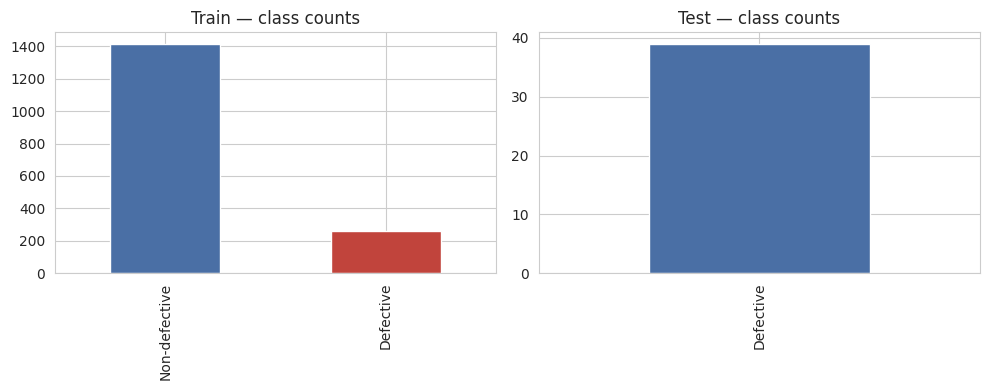

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for a, df, col, title in zip(ax, [train, test], [train_label_col, test_label_col], ["Train", "Test"]):
    to_binary(df[col]).map({1: "Defective", 0: "Non-defective"}).value_counts().plot(
        kind="bar", ax=a, color=["#4A6FA5", "#C1443C"])
    a.set_title(f"{title} — class counts")
    a.set_xlabel("")

plt.tight_layout()
plt.savefig("fig_class_balance.png", dpi=150)
plt.show()

21 shared numeric features


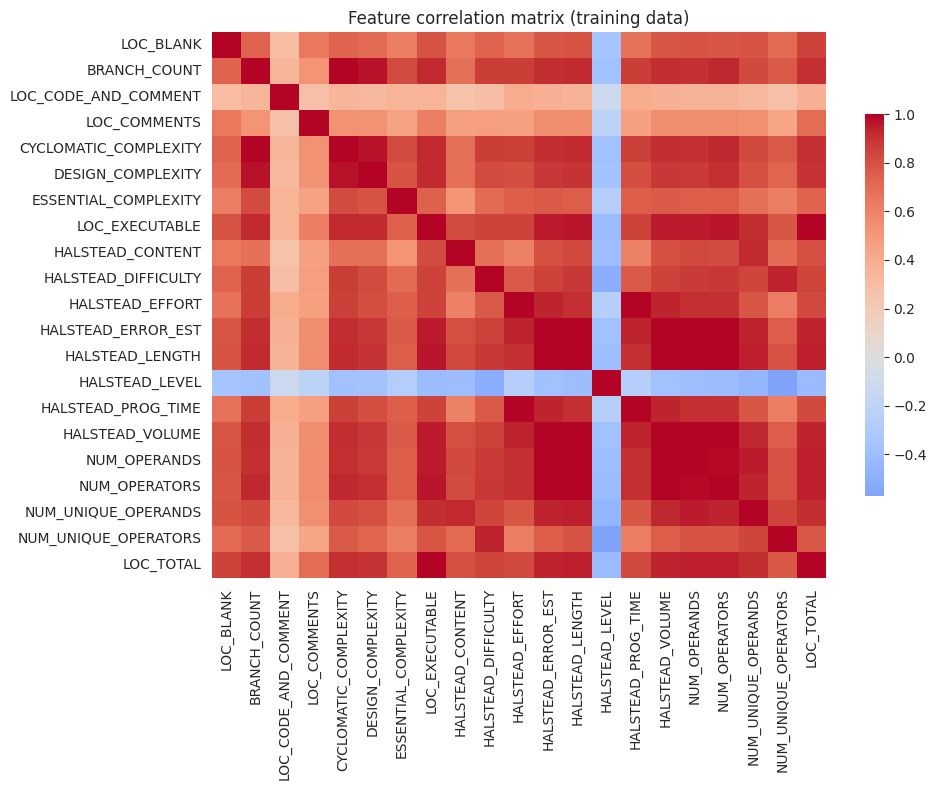

In [6]:
ID_COLS = {"index", "id"}
FEATS = [c for c in train.columns
         if c.lower() not in ID_COLS and c != train_label_col and c in test.columns]
print(f"{len(FEATS)} shared numeric features")

plt.figure(figsize=(10, 8))
sns.heatmap(train[FEATS].corr(), cmap="coolwarm", center=0, cbar_kws={"shrink": 0.7})
plt.title("Feature correlation matrix (training data)")
plt.tight_layout()
plt.savefig("fig_corr_matrix.png", dpi=150)
plt.show()

## 4. Data cleaning (Section 3.4.1)

In [7]:
before = len(train)
train = train.drop_duplicates().reset_index(drop=True)
print(f"duplicates removed: {before - len(train)}")

print("missing (train):", train[FEATS].isna().sum().sum())
print("missing (test):", test[FEATS].isna().sum().sum())

train[FEATS] = train[FEATS].fillna(train[FEATS].median())
test[FEATS] = test[FEATS].fillna(train[FEATS].median())  # test imputed with train stats only

duplicates removed: 0
missing (train): 0
missing (test): 0


In [8]:
X = train[FEATS].copy()
y = to_binary(train[train_label_col]).values

X_test = test[FEATS].copy()
y_test = to_binary(test[test_label_col]).values

print(X.shape, y.mean(), "|", X_test.shape, y_test.mean())

(1676, 21) 0.15513126491646778 | (419, 21) 19.026252983293556


## 5. Pipeline A — ML pre-processing (Section 3.4.2)

Correlation pruning -> RFE -> scaling (SVM only) -> SMOTE.
All steps are fitted inside the pipeline so each transform is fold-safe (fitted on training folds only).

In [9]:
class CorrPruner(BaseEstimator, TransformerMixin):
    """Drops one feature from each pair with |corr| above threshold. Fitted on X only."""
    def __init__(self, thresh=0.9):
        self.thresh = thresh

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        corr = X.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        drop = [c for c in upper.columns if any(upper[c] > self.thresh)]
        self.keep_idx_ = [i for i, c in enumerate(X.columns) if c not in drop]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.iloc[:, self.keep_idx_].values

Feature selection (pruning + RFE) is fitted **once per outer fold**, not once per hyper-parameter
candidate: RFE is a repeated-refit procedure in itself, so nesting it inside the grid/random search would
refit it for every candidate and multiply runtime for no methodological benefit. It is still fitted on the
training portion of each fold only, so no leakage occurs; only the hyper-parameter search for the
classifier (and SMOTE / scaling) is nested inside the tuning step.

In [10]:
def select_features(Xtr, ytr, Xval, k=15):
    """Fit correlation pruning + RFE on the training fold only, apply to both splits."""
    pruner = CorrPruner(0.9).fit(Xtr)
    Xtr_p = pd.DataFrame(pruner.transform(Xtr))
    Xval_p = pd.DataFrame(pruner.transform(Xval))

    rfe = RFE(RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE),
              n_features_to_select=min(k, Xtr_p.shape[1]))
    rfe.fit(Xtr_p, ytr)
    return Xtr_p.loc[:, rfe.support_], Xval_p.loc[:, rfe.support_]


def make_pipeline(clf, scale=False):
    """Tuning pipeline operating on an already feature-selected matrix."""
    steps = []
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

## 6. Models and hyper-parameter search (Sections 3.5, 3.6)

In [11]:
MODELS = {
    "SVM": dict(
        pipe=make_pipeline(SVC(probability=True, random_state=RANDOM_STATE), scale=True),
        grid={"clf__C": [0.1, 1, 10], "clf__kernel": ["rbf", "linear"], "clf__gamma": ["scale", "auto"]},
        search="grid",
    ),
    "Decision Tree": dict(
        pipe=make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        grid={"clf__max_depth": [5, 10, 20, None], "clf__min_samples_split": [2, 5, 10],
              "clf__criterion": ["gini", "entropy"]},
        search="grid",
    ),
    "Random Forest": dict(
        pipe=make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
        grid={"clf__n_estimators": [100, 200, 400], "clf__max_depth": [None, 10, 20],
              "clf__min_samples_split": [2, 5], "clf__max_features": ["sqrt", "log2"]},
        search="random",
    ),
}

## 7. Stratified 10-fold cross-validation (Section 3.6)

Hyper-parameter search is nested inside each outer fold (search runs on the training portion only);
the held-out fold is untouched during tuning.

In [12]:
N_OUTER = 10
outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)

fold_metrics = {m: [] for m in MODELS}
fold_timing = {m: [] for m in MODELS}

for name, spec in MODELS.items():
    print(f"--- {name} ---")
    for fold_i, (tr_idx, val_idx) in enumerate(outer_cv.split(X, y)):
        Xtr, Xval = X.iloc[tr_idx], X.iloc[val_idx]
        ytr, yval = y[tr_idx], y[val_idx]

        Xtr_sel, Xval_sel = select_features(Xtr, ytr, Xval)

        if spec["search"] == "grid":
            searcher = GridSearchCV(spec["pipe"], spec["grid"], scoring="f1", cv=3, n_jobs=-1)
        else:
            searcher = RandomizedSearchCV(spec["pipe"], spec["grid"], scoring="f1", cv=3,
                                           n_iter=10, n_jobs=-1, random_state=RANDOM_STATE)

        t0 = time.time()
        searcher.fit(Xtr_sel, ytr)
        train_time = time.time() - t0

        t0 = time.time()
        pred = searcher.predict(Xval_sel)
        infer_time = (time.time() - t0) / len(Xval_sel)
        proba = searcher.predict_proba(Xval_sel)[:, 1]

        fold_metrics[name].append(dict(
            fold=fold_i,
            accuracy=accuracy_score(yval, pred),
            precision=precision_score(yval, pred, zero_division=0),
            recall=recall_score(yval, pred, zero_division=0),
            f1=f1_score(yval, pred, zero_division=0),
            auc=roc_auc_score(yval, proba),
            mcc=matthews_corrcoef(yval, pred),
        ))
        fold_timing[name].append(dict(train_s=train_time, infer_s=infer_time))

    print(f"  best params (last fold): {searcher.best_params_}")

--- SVM ---
  best params (last fold): {'clf__C': 0.1, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}
--- Decision Tree ---
  best params (last fold): {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_split': 2}
--- Random Forest ---
  best params (last fold): {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 10}


## 8. Evaluation metrics — fold-level results (Section 3.7)

In [13]:
metric_frames = {m: pd.DataFrame(fold_metrics[m]) for m in MODELS}

summary_rows = []
for m in MODELS:
    df = metric_frames[m]
    row = df[["accuracy", "precision", "recall", "f1", "auc", "mcc"]].agg(["mean", "std"]).T
    row.columns = ["mean", "std"]
    row["model"] = m
    summary_rows.append(row)

summary = pd.concat(summary_rows).reset_index().rename(columns={"index": "metric"})
summary_pivot = summary.pivot(index="model", columns="metric", values="mean")
summary_pivot

metric,accuracy,auc,f1,mcc,precision,recall
model,,,,,,
Decision Tree,0.748207,0.733723,0.386100,0.254525,0.319467,0.507692
Random Forest,0.816221,0.782536,0.457852,0.350539,0.427275,0.496154
SVM,0.713630,0.789437,0.443791,0.336807,0.321577,0.730769


In [14]:
timing_summary = pd.DataFrame({
    m: pd.DataFrame(fold_timing[m])[["train_s", "infer_s"]].mean()
    for m in MODELS
}).T
timing_summary.columns = ["mean_train_time_s", "mean_inference_time_s_per_instance"]
timing_summary

,mean_train_time_s,mean_inference_time_s_per_instance
SVM,19.900060,0.000089
Decision Tree,1.213593,0.000009
Random Forest,27.155511,0.000216


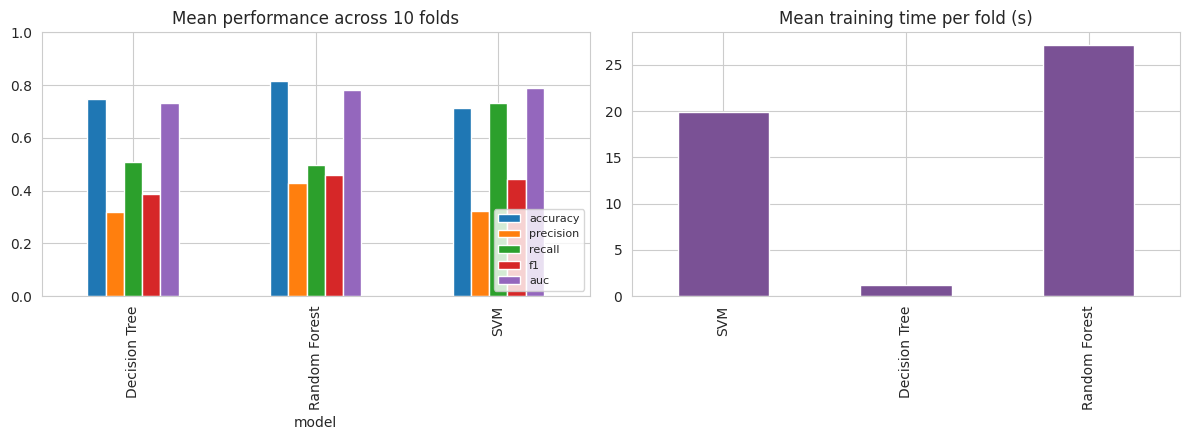

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

summary_pivot[["accuracy", "precision", "recall", "f1", "auc"]].plot(kind="bar", ax=ax[0])
ax[0].set_title("Mean performance across 10 folds")
ax[0].legend(loc="lower right", fontsize=8)
ax[0].set_ylim(0, 1)

timing_summary["mean_train_time_s"].plot(kind="bar", ax=ax[1], color="#7A5195")
ax[1].set_title("Mean training time per fold (s)")

plt.tight_layout()
plt.savefig("fig_model_comparison.png", dpi=150)
plt.show()

## 9. Statistical significance testing (Section 3.8)

Wilcoxon signed-rank test on paired per-fold F1 scores for every model pair, Holm–Bonferroni corrected.

In [16]:
from itertools import combinations

pairs = list(combinations(MODELS.keys(), 2))
raw_p, stats, effect = [], [], []

for a, b in pairs:
    fa = metric_frames[a]["f1"].values
    fb = metric_frames[b]["f1"].values
    stat, p = wilcoxon(fa, fb)
    raw_p.append(p)
    stats.append(stat)
    # matched-pairs rank-biserial effect size
    diffs = fa - fb
    r = 1 - (2 * stat) / (len(diffs) * (len(diffs) + 1) / 2) if len(diffs) > 0 else np.nan
    effect.append(r)

reject, corrected_p, _, _ = multipletests(raw_p, alpha=0.05, method="holm")

sig_table = pd.DataFrame({
    "pair": [f"{a} vs {b}" for a, b in pairs],
    "wilcoxon_stat": stats,
    "raw_p": raw_p,
    "holm_corrected_p": corrected_p,
    "significant (a=0.05)": reject,
    "rank_biserial_effect": effect,
})
sig_table

,pair,wilcoxon_stat,raw_p,holm_corrected_p,significant (a=0.05),rank_biserial_effect
0,SVM vs Decision Tree,6.0,0.027344,0.054688,False,0.781818
1,SVM vs Random Forest,19.0,0.431641,0.431641,False,0.309091
2,Decision Tree vs Random Forest,2.0,0.011719,0.035156,True,0.927273
